# How does a mouse brain turn light into a picture of the world?

This notebook follows visual signals from the thalamus into visual cortex using
Neuropixels recordings from the Allen Brain Observatory, Visual Coding
Neuropixels dataset ([DANDI:000021](https://dandiarchive.org/dandiset/000021)).
Awake, head-fixed mice watched a fixed battery of visual stimuli while up to six
probes recorded spikes from the visual thalamus (LGN, labelled `LGd`) and six
visual cortical areas: primary visual cortex (V1, `VISp`) and the higher areas
LM, RL, AL, PM and AM.

We use 13 of the 32 sessions, those with at least 40 well-isolated units in both
LGN and V1, and ask four questions, one per stimulus:

1. Timing (full-field flashes): in what order do areas respond?
2. Space (small Gabor patches on a grid): which part of the visual field does each neuron watch?
3. Features (drifting gratings): which areas care about edge orientation?
4. The picture (118 natural photographs): can we tell which photo the mouse saw from its neurons?

Each step lives in its own script (`02_...py` to `05_...py`); this notebook runs
them in order and shows their outputs.

## Setup and data loading

`common.py` streams each session's NWB file from DANDI with `remfile` + `h5py`,
keeps only LGN and visual-cortex units that pass the Allen Institute's default
quality thresholds (ISI violations < 0.5, amplitude cutoff < 0.1, presence
ratio > 0.9), and caches spike times locally (about 1 minute per session the first
time). Spikes become a pynapple `TsGroup` with each unit's area and probe as
metadata; each stimulus table becomes a pynapple `IntervalSet`.

Some probes stop recording for long stretches. Periods listed in the file's
`invalid_times` table, plus any gap longer than 5 s with no spikes on a whole
probe, are treated as invalid, and trials that overlap them are dropped for that
probe's units.

In [1]:
import importlib

import pandas as pd
from IPython.display import Image, display

from common import AREAS, SESSIONS, load_session

step = {n: importlib.import_module(m) for n, m in [
    (1, "01_load_data"), (2, "02_flash_latency"), (3, "03_receptive_fields"),
    (4, "04_orientation_tuning"), (5, "05_natural_scene_decoding")]}
print(f"{len(SESSIONS)} sessions")

13 sessions


In [2]:
units, stims, invalid = load_session(step[1].SESSION)
step[1].summarize(units, stims, invalid)

/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: start is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)
/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: end is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)


    Index      rate  area      depth    waveform_duration    snr  probe
---------  --------  ------  -------  -------------------  -----  -------
950911861   9.71574  VISam      2500                 0.25   1.7   probeA
950911873   2.60302  VISam      2540                 0.92   2.1   probeA
950911880   8.99758  VISam      2540                 0.27   3.77  probeA
950911932   4.60826  VISam      2580                 0.73   1.95  probeA
950911986   3.48745  VISam      2640                 0.59   2.3   probeA
950912018  14.9691   VISam      2640                 0.66   1.86  probeA
950912052   0.61295  VISam      2640                 0.58   2.77  probeA
950912065   4.88274  VISam      2660                 0.43   2.92  probeA
950912109   3.48943  VISam      2680                 1.32   1.97  probeA
950912164   6.01331  VISam      2760                 0.65   2.54  probeA
950912190   5.45436  VISam      2760                 0.59   3.69  probeA
950912214   3.26479  VISam      2760               

/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(


### Raw data

Every quality-filtered unit in one session over 1.5 s, while six natural images
were flashed back to back. Firing is sparse and ongoing; each image evokes a
volley of spikes in V1 and other areas.

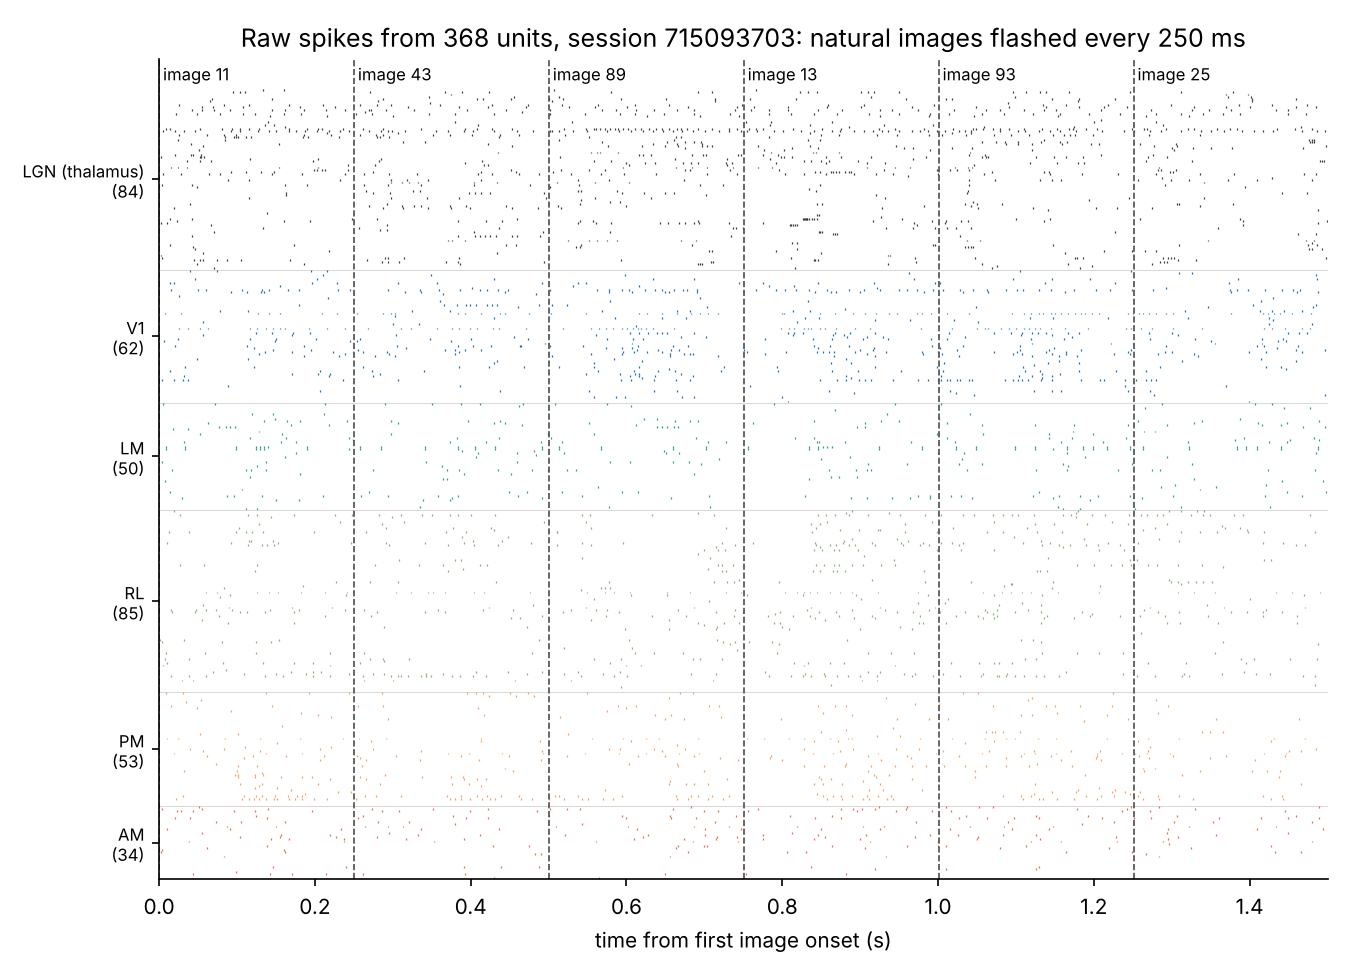

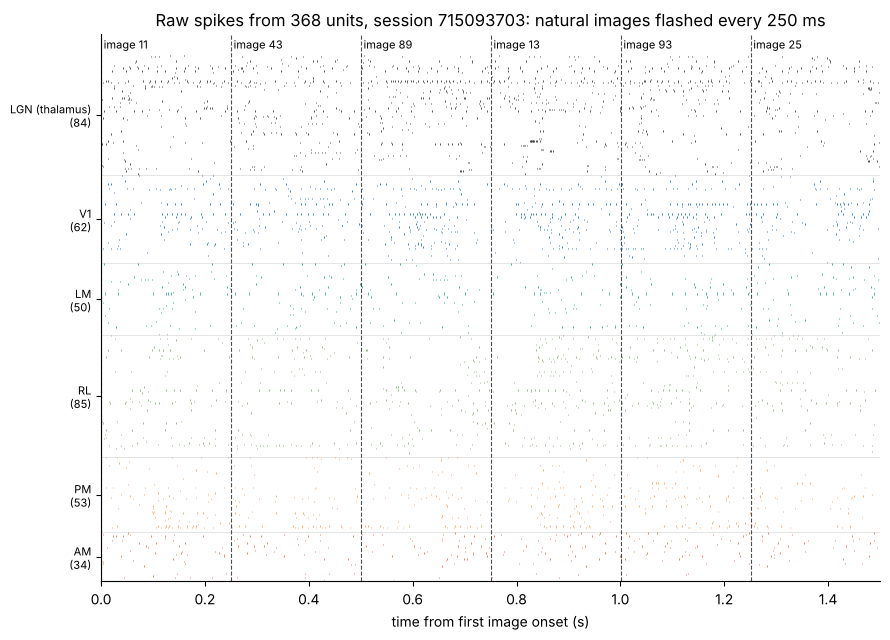

In [3]:
step[1].plot_raw(units, stims)
display(Image("figures/01_raw_raster.png"))

## 1. Timing: signals flow from thalamus to V1 to higher areas

For each session and area, all units are pooled into one population PSTH around
150 full-screen white or black flashes. The latency is when that population rate
first reaches half its peak.

flash latency:   0%|          | 0/13 [00:00<?, ?it/s]

/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: start is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)
/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: end is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)


/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(
flash latency:   8%|▊         | 1/13 [00:04<00:49,  4.09s/it]

/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(
flash latency:  15%|█▌        | 2/13 [00:05<00:29,  2.65s/it]

/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: start is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)
/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: end is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)
/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: Some starts precede the previous end. Joining them!
  invalid[p] = nap.IntervalSet(start, end)


...

/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(
flash latency:  85%|████████▍ | 11/13 [00:30<00:05,  2.80s/it]

/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(
flash latency:  92%|█████████▏| 12/13 [00:34<00:03,  3.03s/it]

/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(
flash latency: 100%|██████████| 13/13 [00:36<00:00,  2.98s/it]

flash latency: 100%|██████████| 13/13 [00:36<00:00,  2.84s/it]

       n_sessions  total_units  median_latency_ms   q25   q75
area                                                         
LGd            13          852               37.5  35.5  41.5
VISp           12          851               44.0  41.3  44.8
VISl           10          384               50.0  47.3  51.3
VISrl          11          672               50.5  47.0  55.5
VISal           8          534               48.0  43.5  50.8
VISpm           8          388               60.5  52.5  66.3
VISam          10          643               56.0  47.5  58.8
LGN earlier than V1 in 8/12 sessions; median difference 5.5 ms


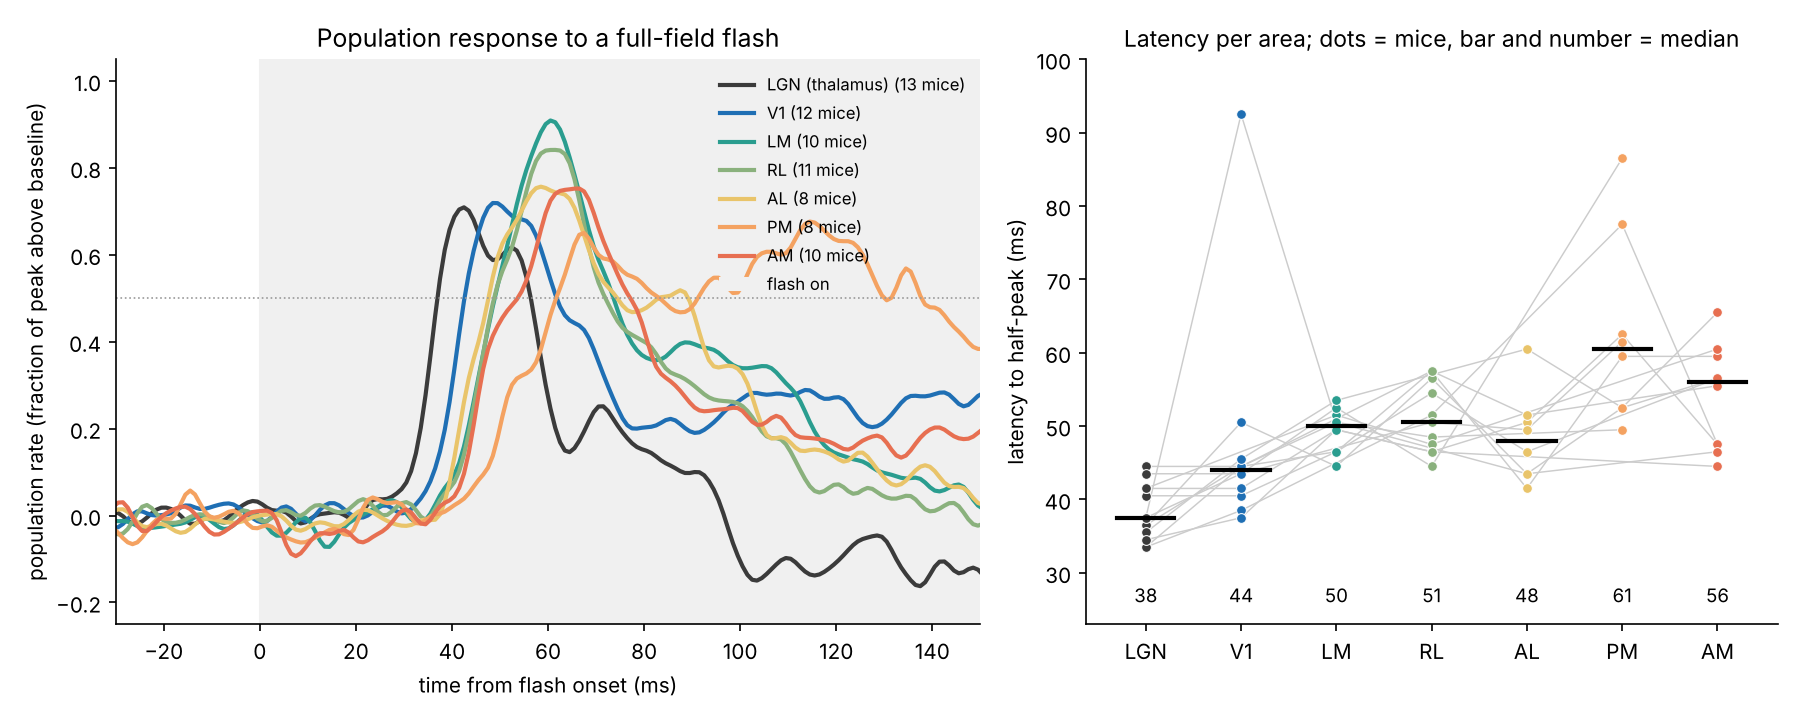

,n_sessions,total_units,median_latency_ms,q25,q75
area,,,,,
LGd,13,852,37.5,35.5,41.5
VISp,12,851,44.0,41.3,44.8
VISl,10,384,50.0,47.3,51.3
VISrl,11,672,50.5,47.0,55.5
VISal,8,534,48.0,43.5,50.8
VISpm,8,388,60.5,52.5,66.3
VISam,10,643,56.0,47.5,58.8


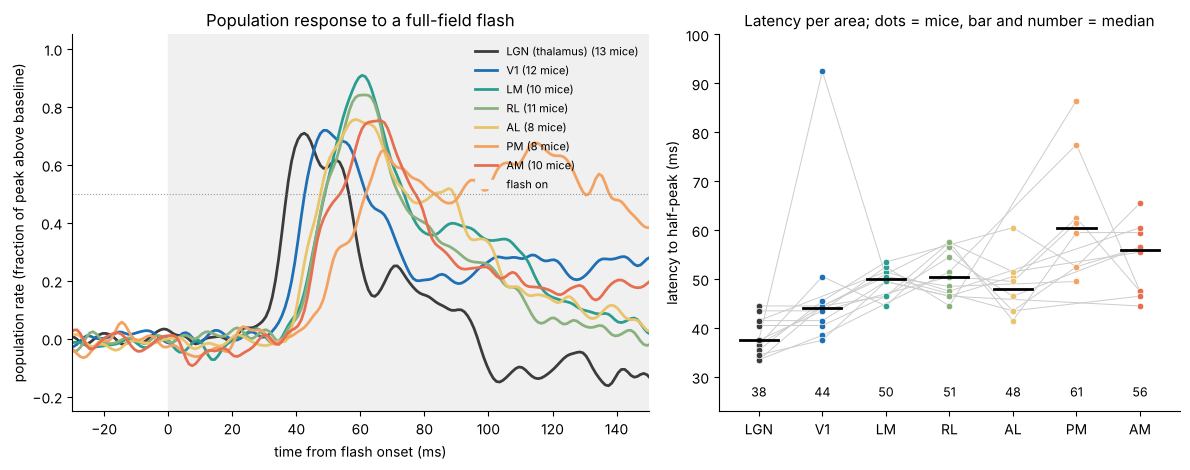

In [4]:
step[2].main()
display(Image("figures/02_flash_latency.png"))
pd.read_csv("results/flash_latency_summary.csv", index_col=0).round(1)

LGN responds first (median 38 ms after the flash), V1 next (44 ms), then LM, RL
and AL (48-51 ms), and finally PM and AM (56-61 ms). LGN led V1 in 8 of the 12
mice where both were recorded, with a median lead of 5.5 ms. This ordering
matches the anatomical hierarchy: retina to LGN to V1 to higher visual areas.
One V1 recording (session 799864342) responded weakly to flashes, which pushed
its half-peak time to 92 ms.

## 2. Space: each neuron sees one patch of the world

Gabor patches 20 degrees across were flashed at 81 positions on a 9 x 9 grid.
Averaging each unit's response per position gives its receptive-field (RF) map.

receptive fields:   0%|          | 0/13 [00:00<?, ?it/s]

/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: start is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)
/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: end is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)


/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(


receptive fields:   8%|▊         | 1/13 [00:14<02:59, 14.92s/it]

receptive fields:  15%|█▌        | 2/13 [00:27<02:28, 13.52s/it]

...

receptive fields:  85%|████████▍ | 11/13 [02:57<00:36, 18.09s/it]

receptive fields:  92%|█████████▏| 12/13 [03:14<00:17, 17.61s/it]

receptive fields: 100%|██████████| 13/13 [03:30<00:00, 17.12s/it]

receptive fields: 100%|██████████| 13/13 [03:30<00:00, 16.16s/it]

       n_units  frac_with_rf  median_rf_area_deg2
area                                             
LGd        852          0.65               1100.0
VISp       851          0.83                700.0
VISl       384          0.82               1100.0
VISrl      703          0.69               1100.0
VISal      534          0.72               1100.0
VISpm      457          0.73               1200.0
VISam      717          0.70               1400.0


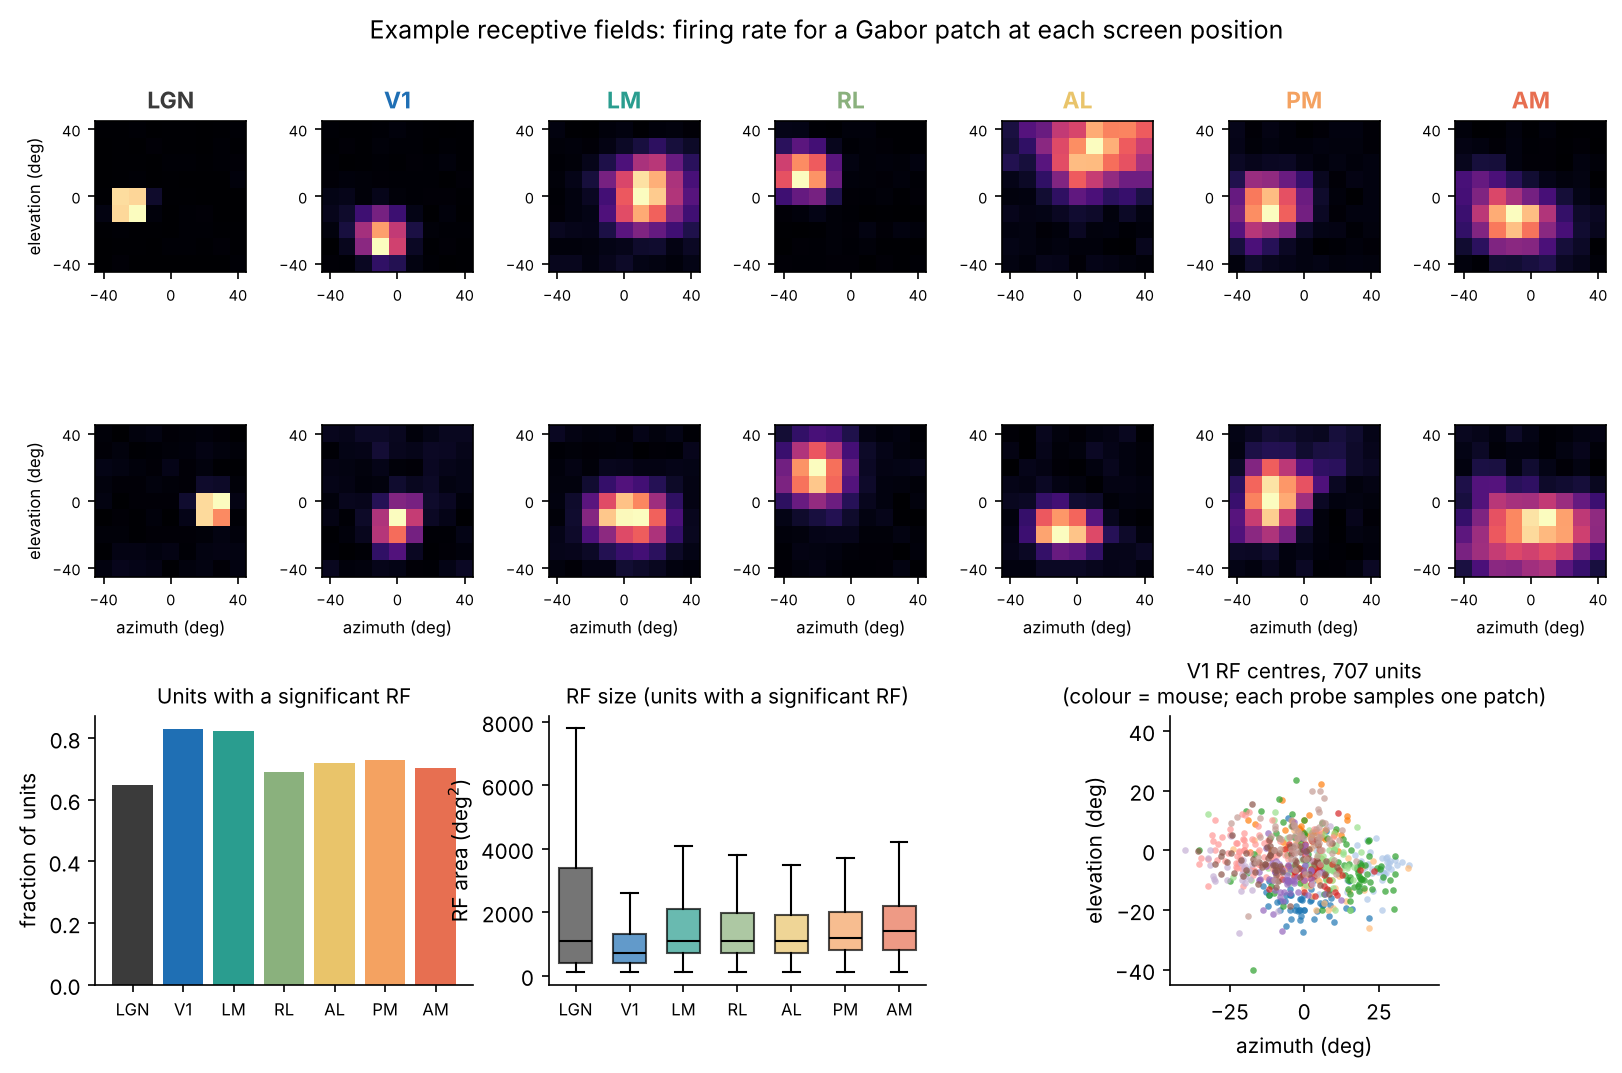

,n_units,frac_with_rf,median_rf_area_deg2
area,,,
LGd,852,0.65,1100.0
VISp,851,0.83,700.0
VISl,384,0.82,1100.0
VISrl,703,0.69,1100.0
VISal,534,0.72,1100.0
VISpm,457,0.73,1200.0
VISam,717,0.70,1400.0


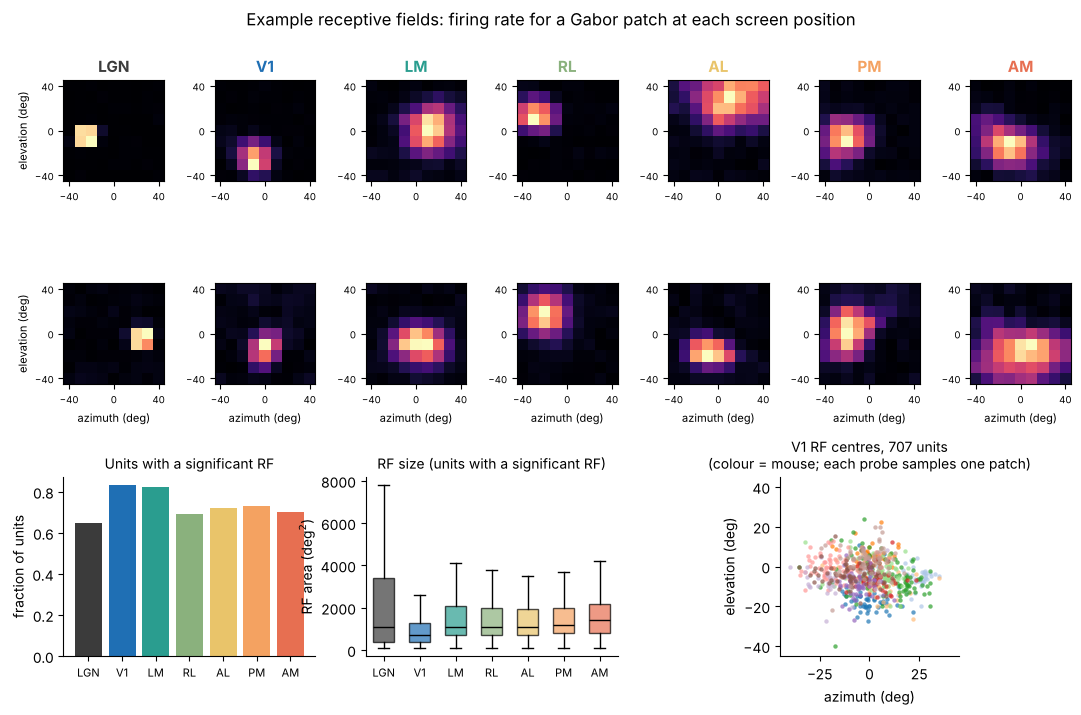

In [5]:
step[3].main()
display(Image("figures/03_receptive_fields.png"))
pd.read_csv("results/receptive_fields_summary.csv", index_col=0).round(2)

Most units (65% in LGN, 83% in V1, 69-82% in higher areas) respond to only part of
the screen. Neighbouring V1 units share nearby RFs, and recordings from different
mice cover different patches (bottom right), so the population as a whole tiles
the visual field, much like pixels. RFs are smallest in V1 (median about
700 deg²) and larger in higher areas (1100-1400 deg²), so higher areas pool
information over more of the scene. The grid spacing is 10 degrees and the
patches are 20 degrees wide, so these sizes are coarse upper estimates. LGN's
median looks large because many LGN maps are weak and broad under this measure.

## 3. Features: orientation selectivity appears in cortex

Full-screen gratings drifted in 8 directions at 5 speeds. For each unit we use its
preferred speed and compute a global orientation selectivity index (OSI) from its
mean firing rate in each direction.

orientation tuning:   0%|          | 0/13 [00:00<?, ?it/s]

/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: start is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)
/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: end is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)


/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(


orientation tuning:   8%|▊         | 1/13 [00:05<01:07,  5.60s/it]

orientation tuning:  15%|█▌        | 2/13 [00:08<00:46,  4.19s/it]

...

orientation tuning:  85%|████████▍ | 11/13 [00:47<00:09,  4.79s/it]

orientation tuning:  92%|█████████▏| 12/13 [00:50<00:04,  4.31s/it]

orientation tuning: 100%|██████████| 13/13 [00:54<00:00,  4.26s/it]

orientation tuning: 100%|██████████| 13/13 [00:54<00:00,  4.20s/it]

       n_units  frac_responsive  median_osi  median_dsi  frac_osi_above_0_3
area                                                                       
LGd        852            0.608       0.091       0.075               0.023
VISp       910            0.703       0.249       0.095               0.414
VISl       384            0.771       0.210       0.093               0.358
VISrl      703            0.738       0.222       0.102               0.353
VISal      534            0.757       0.203       0.090               0.304
VISpm      457            0.726       0.203       0.087               0.349
VISam      751            0.692       0.190       0.095               0.283


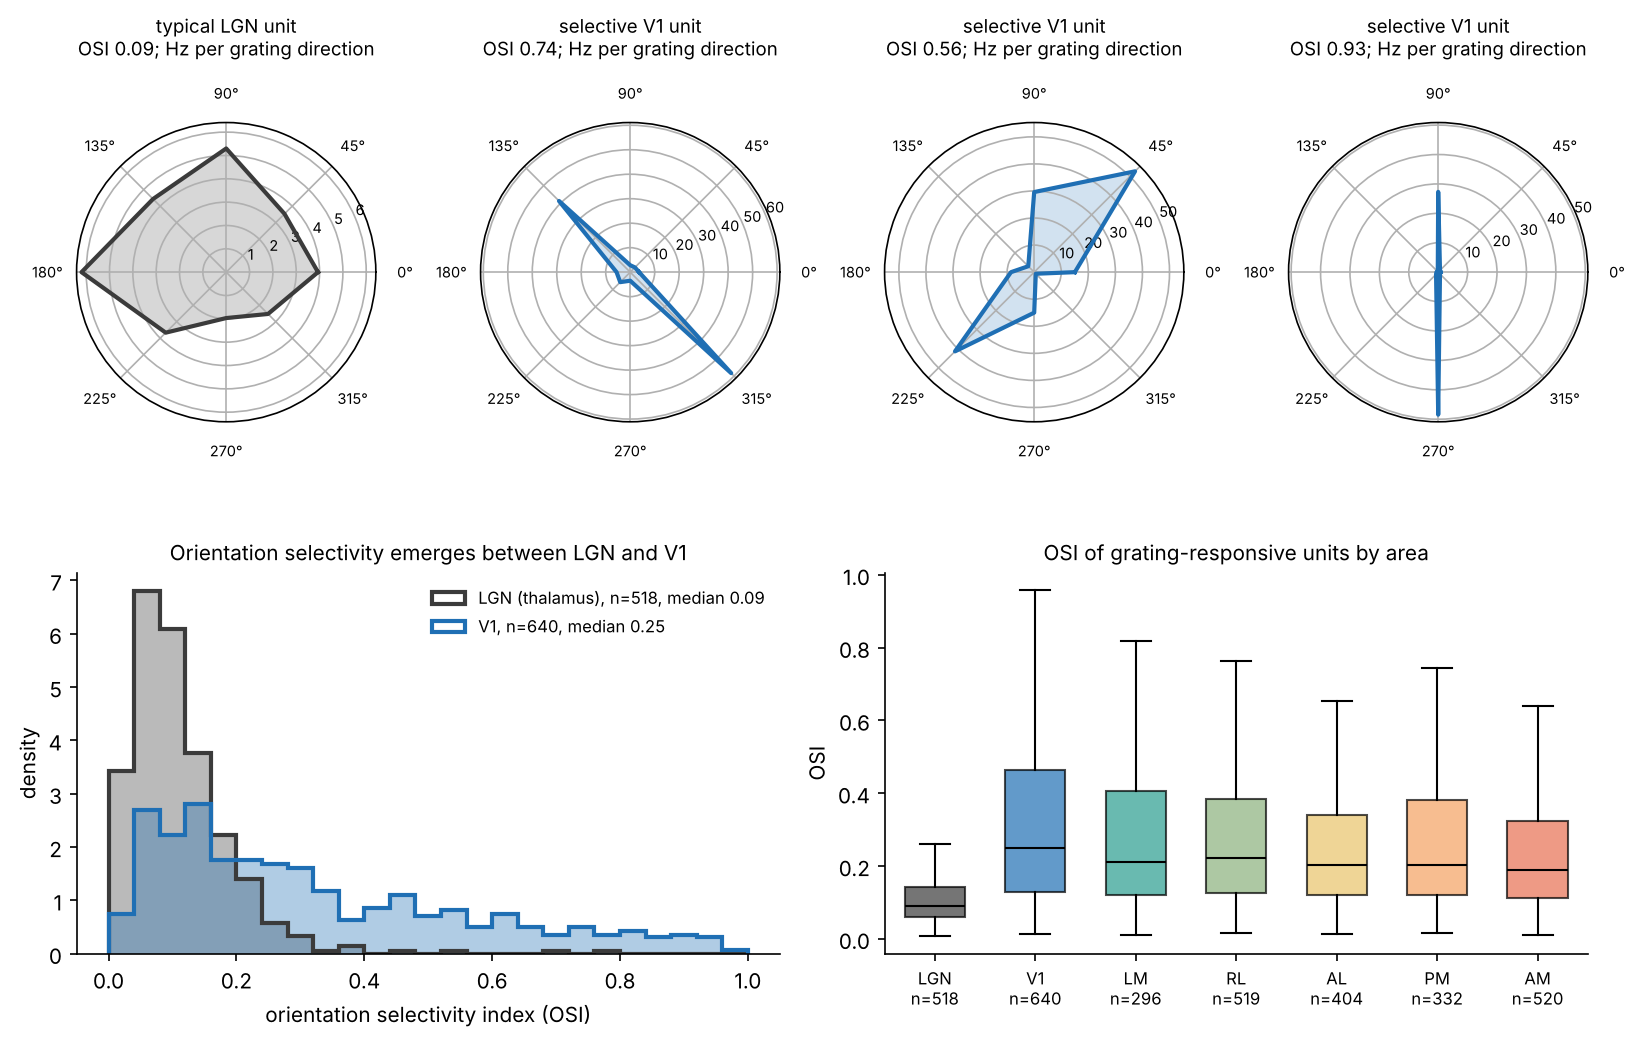

,n_units,frac_responsive,median_osi,median_dsi,frac_osi_above_0_3
area,,,,,
LGd,852,0.608,0.091,0.075,0.023
VISp,910,0.703,0.249,0.095,0.414
VISl,384,0.771,0.210,0.093,0.358
VISrl,703,0.738,0.222,0.102,0.353
VISal,534,0.757,0.203,0.090,0.304
VISpm,457,0.726,0.203,0.087,0.349
VISam,751,0.692,0.190,0.095,0.283


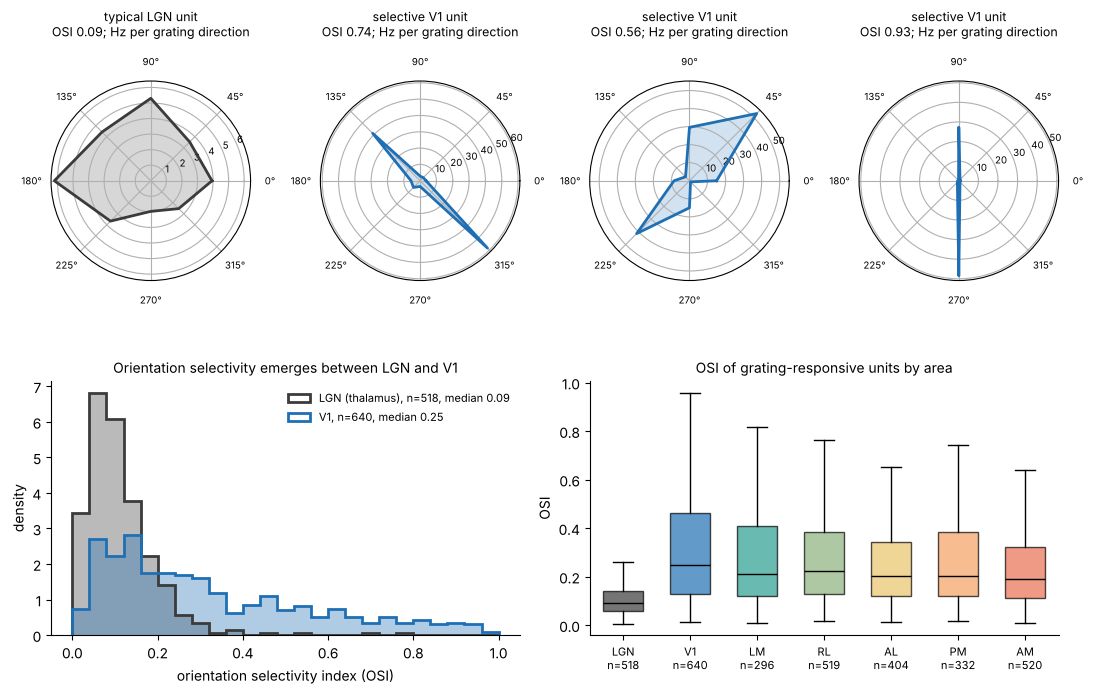

In [6]:
step[4].main()
display(Image("figures/04_orientation_tuning.png"))
pd.read_csv("results/orientation_tuning_summary.csv", index_col=0).round(3)

LGN units barely care about orientation (median OSI 0.09; only 2% above 0.3). In V1
the median OSI is 0.25 and 41% of units exceed 0.3, with some responding almost
only to one orientation. Higher areas keep this property (medians 0.19-0.22).
This is the classic transformation from spot-like thalamic inputs to
edge-detecting cortical neurons, the first step in describing shapes.

## 4. The picture: neural populations identify natural images

Each of 118 photographs was flashed about 50 times. A Poisson naive-Bayes decoder
learns each image's average population response from some repeats and names the
image on held-out repeats. Chance is 1 in 118 (0.85%).

natural scenes:   0%|          | 0/13 [00:00<?, ?it/s]

/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: start is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)
/home/user/dandi-showcase-runs/vision_e/common.py:162: UserWarning: end is not sorted. Sorting it.
  invalid[p] = nap.IntervalSet(start, end)


/home/user/dandi-showcase-runs/vision_e/common.py:165: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  stims[name.replace("_presentations", "")] = nap.IntervalSet(


natural scenes:   8%|▊         | 1/13 [00:06<01:16,  6.41s/it]

natural scenes:  15%|█▌        | 2/13 [00:11<01:03,  5.80s/it]

...

natural scenes:  92%|█████████▏| 12/13 [01:18<00:06,  6.92s/it]

natural scenes: 100%|██████████| 13/13 [01:25<00:00,  6.90s/it]

natural scenes: 100%|██████████| 13/13 [01:25<00:00,  6.56s/it]

       count  median    min    max
area                              
LGd       13   0.226  0.053  0.479
VISp      12   0.302  0.165  0.511
VISl       8   0.272  0.131  0.409
VISrl     10   0.116  0.051  0.321
VISal      7   0.192  0.095  0.374
VISpm      7   0.211  0.053  0.405
VISam     12   0.133  0.039  0.345


n_units    1      3      10     30     100    300
area                                             
LGd      0.013  0.024  0.056  0.219  0.732  0.973
VISp     0.017  0.033  0.116  0.329  0.792  0.967
VISl     0.013  0.029  0.094  0.269  0.700  0.935
VISrl    0.014  0.023  0.058  0.150  0.456  0.755
VISal    0.017  0.026  0.090  0.208  0.585  0.882
VISpm    0.013  0.026  0.058  0.181  0.510  0.791
VISam    0.013  0.027  0.052  0.129  0.405  0.719


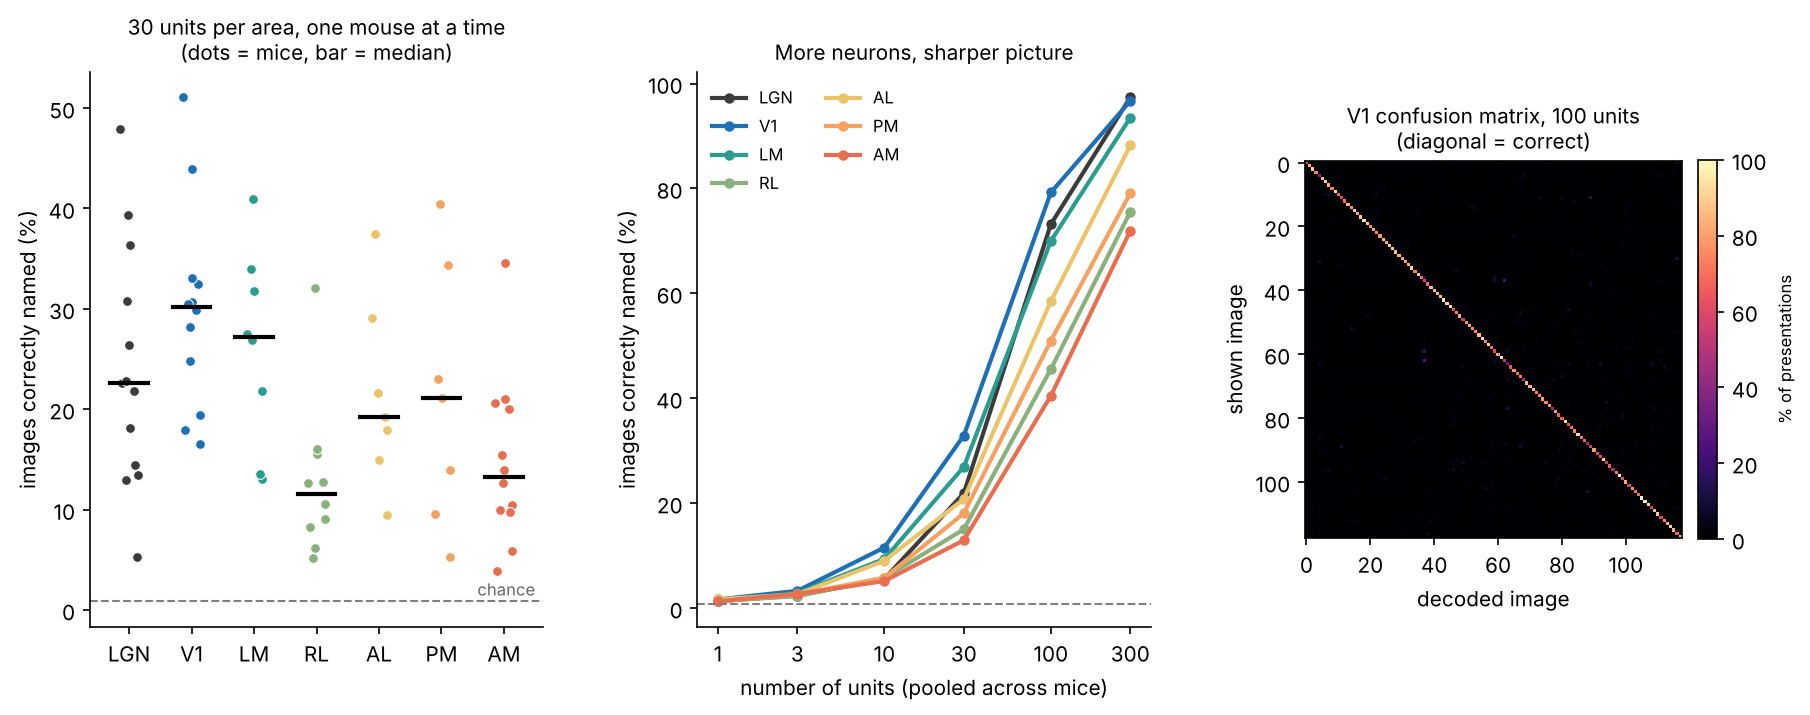

n_units,1,3,10,30,100,300
area,,,,,,
LGd,0.013,0.024,0.056,0.219,0.732,0.973
VISp,0.017,0.033,0.116,0.329,0.792,0.967
VISl,0.013,0.029,0.094,0.269,0.700,0.935
VISrl,0.014,0.023,0.058,0.150,0.456,0.755
VISal,0.017,0.026,0.090,0.208,0.585,0.882
VISpm,0.013,0.026,0.058,0.181,0.510,0.791
VISam,0.013,0.027,0.052,0.129,0.405,0.719


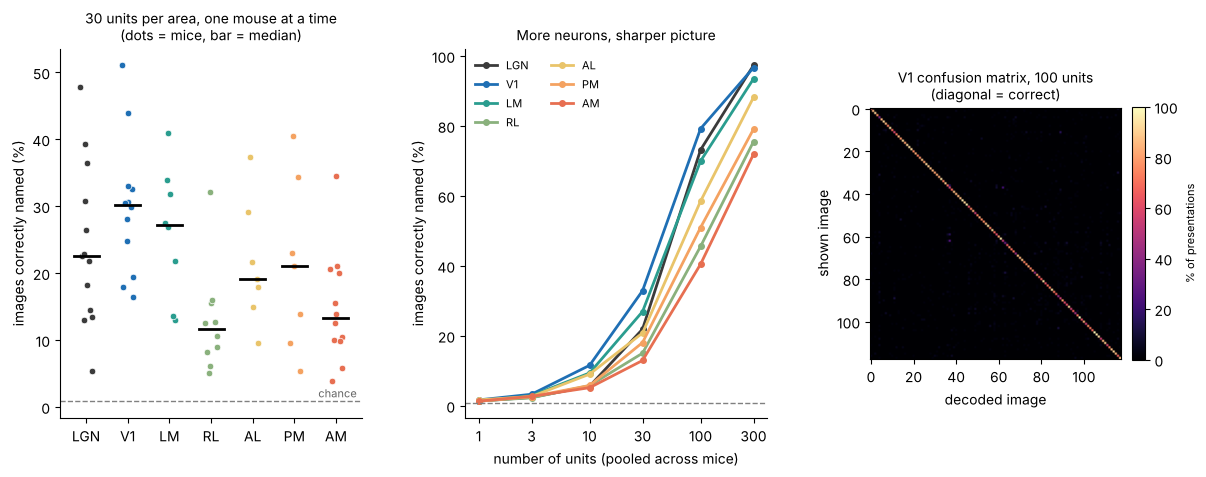

In [7]:
step[5].main()
display(Image("figures/05_natural_scene_decoding.png"))
pd.read_csv("results/decoding_vs_population_size.csv").groupby(["area", "n_units"])["accuracy"].mean() \
    .unstack().reindex(AREAS).round(3)

With only 30 units, V1 names the correct photo on a median of 30% of
presentations, about 35 times chance. Every area does far better than chance.
Pooling units across mice (possible because every mouse saw the same photos)
shows accuracy rising steeply with population size: 300 LGN or V1 units identify
the image on about 97% of single 250 ms glimpses. LM follows closely (94%), and
AL, PM, RL and AM are lower (72-88%). One caveat is that pooling across mice
ignores correlated noise between neurons recorded together, which can raise
accuracy above what a single brain achieves.

LGN carries nearly as much image-specific information as V1. Cortex does not
add information about the image; it re-formats it. LGN describes the scene point
by point, while V1 and later areas describe it with oriented edges in larger and
larger patches of space, a format that makes shapes and objects easier to read
out.

## Summary

Light hitting the retina reaches the LGN in under 40 ms and V1 about 5 ms later,
then spreads through higher visual areas over the next 10-20 ms. Along the way:

- each neuron reports on one patch of the visual field, and together they tile it;
- V1 converts LGN's mostly orientation-blind signals into edge-orientation
  detectors, and higher areas pool over larger regions;
- a few hundred neurons, in thalamus or cortex, carry enough information to
  tell which of 118 photographs the mouse is looking at from a single glimpse.

The "picture of the world" is distributed across many neurons. No single neuron
holds it, but the population code can be read out with a simple decoder.